### Z-score method
This method is only used to handle outliers when the distribution is normal or close to normal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/home/ammar/AI Track/Machine-Learning/Outliers/Datasets/placement.csv')

In [3]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


<Axes: xlabel='cgpa', ylabel='Density'>

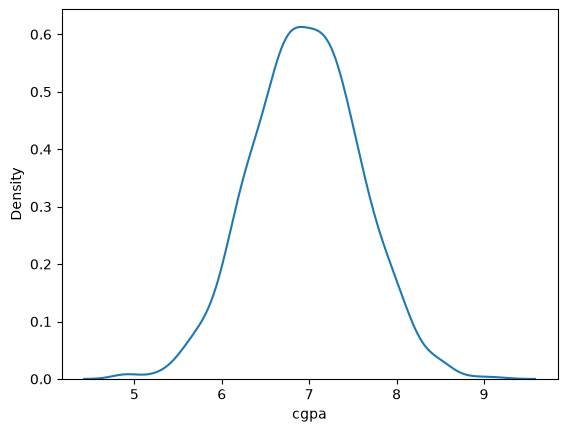

In [4]:
sns.kdeplot(df['cgpa'])

<Axes: xlabel='placement_exam_marks', ylabel='Density'>

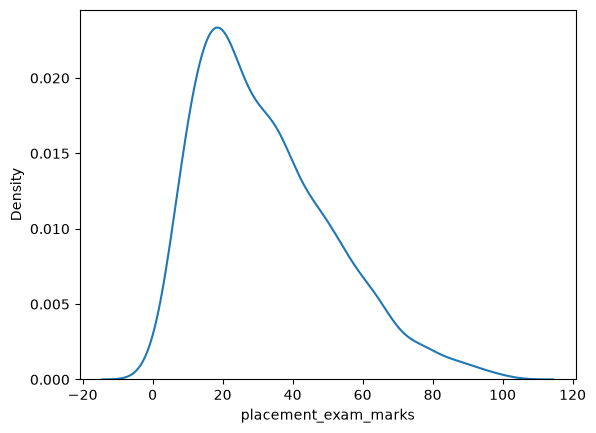

In [6]:
sns.kdeplot(df['placement_exam_marks'])
# we cannot apply z-score method on this distribution because it is not normal

### Trimming 

In [17]:
print(df['cgpa'].mean()+df['cgpa'].std()*3)
print(df['cgpa'].mean()-df['cgpa'].std()*3)
#this is 3+σ and 3-σ

8.763601707753606
5.163111860085589


In [13]:
df = df[(df['cgpa']<df['cgpa'].mean()+df['cgpa'].std()*3) & (df['cgpa']>df['cgpa'].mean()-df['cgpa'].std()*3)]

In [16]:
df.describe()

,cgpa,placement_exam_marks,placed
count,995.000000,995.000000,995.000000
mean,6.963357,32.188945,0.487437
std,0.600082,19.130298,0.500094
min,5.230000,0.000000,0.000000
25%,6.550000,17.000000,0.000000
50%,6.960000,28.000000,0.000000
75%,7.365000,44.000000,1.000000
max,8.620000,100.000000,1.000000


### Capping
I have capped those values which are above and below 3 + σ and 3 - σ respectively

In [24]:
df['cgpa'] = np.array(df['cgpa']).clip(df['cgpa'].mean()-df['cgpa'].std()*3,df['cgpa'].mean()+df['cgpa'].std()*3)

In [27]:
df.head()

,cgpa,placement_exam_marks,placed,cgpq
0,7.19,26.0,1,7.19
1,7.46,38.0,1,7.46
2,7.54,40.0,1,7.54
3,6.42,8.0,1,6.42
4,7.23,17.0,0,7.23
